# An Explainable Machine Learning System for Predicting High Electricity Consumption Risk in Sri Lankan Households

This notebook is the main backend implementation. It uses real RECON-SL monthly consumption and Wave 1 household survey data. All model results shown below are produced by the code, not typed by hand.

## 1. Project introduction

Electricity bills are an important concern for Sri Lankan households. A household may not know whether its recent pattern and appliance use will lead to high use next month. This tool may help households notice risk early, but it cannot predict an exact bill and it should not replace professional advice.

**Final problem statement:** “This project predicts whether a Sri Lankan household is at risk of having high electricity consumption in the following month.”

## 2. Research question

**Main question:** “Can CatBoost predict next-month high electricity consumption risk for Sri Lankan households more effectively than Logistic Regression, Decision Tree, Random Forest and XGBoost?”

Supporting questions ask which household and appliance features matter, whether CatBoost handles categories well, whether a hybrid helps, and whether an ordinary user can understand the estimate.

## 3. Classification justification

**This is a binary classification problem because the output contains two classes: normal consumption risk and high consumption risk.** Predicting an exact kWh value would be regression. This implementation predicts a risk category for the following month.

## 4. Import libraries and run the reproducible backend

A fixed seed of 42 is used where supported. The next cell runs the same backend used by the application and regenerates the tables, figures, and saved model.

In [1]:
from pathlib import Path
import sys, json, runpy, warnings
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown

ROOT = Path('..').resolve()
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
np.random.seed(42)
runpy.run_path(str(ROOT / 'train_project.py'), run_name='__main__')
print('Backend completed with random seed 42.')

/Users/sasitha/.local/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


/Users/sasitha/Desktop/Kee/Sem2/sri-lanka-energy-risk/train_project.py:384: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(forest_shap, transformed, feature_names=transformed_names, show=False, max_display=15, plot_size=(9,6)); plt.title(f"{final_name}: SHAP summary"); save_figure("16_shap_summary.png")


/Users/sasitha/Desktop/Kee/Sem2/sri-lanka-energy-risk/train_project.py:385: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(forest_shap, transformed, feature_names=transformed_names, plot_type="bar", show=False, max_display=15, plot_size=(9,6)); plt.title(f"{final_name}: mean absolute SHAP values"); save_figure("17_shap_bar.png")


{
  "final_model": "Random Forest",
  "records": 26937,
  "households": 3776,
  "test_metrics": {
    "Accuracy": 0.9013035381750466,
    "Balanced Accuracy": 0.9033721556956389,
    "Precision": 0.9380614657210402,
    "Recall": 0.8920863309352518,
    "F1": 0.9144964277483291,
    "ROC-AUC": 0.963221474937314,
    "PR-AUC": 0.9723020160999069,
    "Training Time": 0.5690366659982828,
    "Prediction Time": 0.032534291996853426
  },
  "model_path": "/Users/sasitha/Desktop/Kee/Sem2/sri-lanka-energy-risk/models/energy_risk_model.pkl"
}
Backend completed with random seed 42.


## 5. Load and inspect data

The audit first checks every downloaded CSV. High-frequency smart meter files were intentionally not downloaded because the monthly task does not need millions of interval rows.

In [2]:
raw = pd.read_csv(ROOT/'data/raw/consumption/monthly_consumption.csv', low_memory=False)
display(raw.head())
display(raw.tail())
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.dtypes.rename('dtype').to_frame())
display(raw.describe(include='all'))
audit = pd.read_csv(ROOT/'outputs/tables/dataset_audit.csv')
display(audit)
print('Duplicate rows:', raw.duplicated().sum())
print('Unique households:', raw.household_ID.nunique())
print('Records per household:', raw.groupby('household_ID').size().describe().to_dict())

,household_ID,month,consumption
0,ID0001,2022-10-31,116
1,ID0001,2022-11-30,120
2,ID0001,2022-12-31,129
3,ID0001,2023-01-31,102
4,ID0001,2023-02-28,115


,household_ID,month,consumption
101570,ID4063,2024-06-30,167
101571,ID4063,2024-07-31,178
101572,ID4063,2024-08-31,165
101573,ID4063,2024-09-30,124
101574,ID4063,2024-10-31,109


Shape: (101575, 3)
Columns: ['household_ID', 'month', 'consumption']


,dtype
household_ID,object
month,object
consumption,object


,household_ID,month,consumption
count,101575,101575,100985
unique,4063,25,1134
top,ID0001,2022-10-31,0
freq,25,4063,2332


,Filename,Rows,Columns,Possible household identifier,Possible date field,Possible consumption field,Useful household or appliance fields,Missing-value percentage,Will be used,Reason
0,consumption/monthly_consumption.csv,101575,3,household_ID,month,consumption,"month, consumption",0.19,Yes,"Used for monthly history, survey availability,..."
1,documentation/consumption_data_dictionary.csv,55,5,NaN,NaN,NaN,"column_name, data_type, missing_values, descri...",9.09,Yes,Used to confirm column names and meanings
2,documentation/wave_1_data_dictionary.csv,121,4,NaN,NaN,NaN,"column_name, data_type, missing_values",0.00,Yes,Used to confirm column names and meanings
3,survey/survey_dates.csv,4063,5,household_ID,wave1,NaN,"household_ID, wave1, wave2, wave3",5.98,Yes,"Used for monthly history, survey availability,..."
4,survey/wave_1/w1_ac_roster.csv,1171,10,household_ID,NaN,NaN,"room_ID, ac_ID, type_of_the_ac, is_the_ac_inve...",7.76,Yes,"Used for monthly history, survey availability,..."
5,survey/wave_1/w1_appliances.csv,53599,4,household_ID,NaN,NaN,"appliance_ID, appliance_type, no_of_hours_used...",10.16,Yes,"Used for monthly history, survey availability,..."
6,survey/wave_1/w1_demographics.csv,16270,16,household_ID,NaN,NaN,"member_ID, age, relationship_to_the_head_of_ho...",17.36,No,Audited but not used; member-level demographic...
7,survey/wave_1/w1_electricity_generation_water_...,4063,36,household_ID,NaN,NaN,"have_backup_generator, generate_electicity_usi...",35.62,Yes,"Used for monthly history, survey availability,..."
8,survey/wave_1/w1_household_information_and_his...,4063,26,household_ID,total_monthly_expenditure_of_last_month,awareness_of_electricity_consumption_of_renters,"no_of_electricity_meters, electricity_provider...",26.17,Yes,"Used for monthly history, survey availability,..."


Duplicate rows: 0
Unique households: 4063
Records per household: {'count': 4063.0, 'mean': 25.0, 'std': 0.0, 'min': 25.0, '25%': 25.0, '50%': 25.0, '75%': 25.0, 'max': 25.0}


## 6. Data quality analysis

Comma-formatted readings are repaired before numeric conversion. Missing values are kept until a row needs a lag or target. No data is deleted without a recorded reason.

,Issue,Affected records,Percentage,Action taken,Reason
0,Missing monthly consumption,590,0.580852,Excluded only when needed for lag or target,A model cannot learn from an unknown monthly r...
1,Comma-formatted consumption,57,0.056116,Removed comma before numeric conversion,"These are valid large values, not missing values"
2,Invalid date format,0,0.000000,Would exclude invalid dates,Month order is required for safe lag features
3,Negative consumption,0,0.000000,No action,No invalid negative readings were found
4,Duplicate household-month,0,0.000000,No action,Each household-month key is unique
5,Impossible household size (<1 or >30),0,0.000000,Would set to missing,Impossible values should not enter the model
6,Negative appliance count,0,0.000000,Would set to missing,Counts cannot be negative
7,Extreme consumption above the 99.9th percentile,101,0.100015,Flagged but retained,High readings may be genuine and should not be...
8,Rows unavailable before Wave 1 survey/history/...,74638,73.480679,Removed from modelling,Prevents future survey information and incompl...


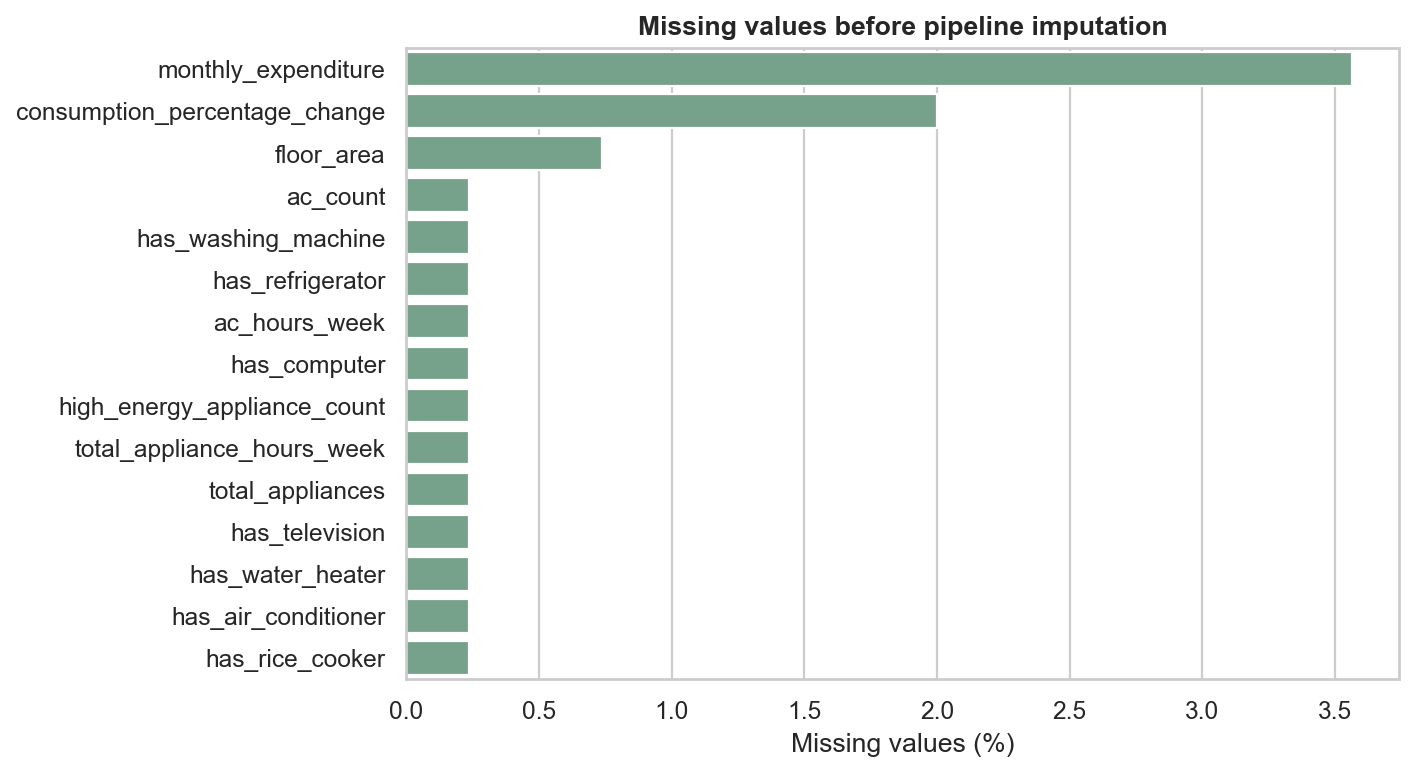

Interpretation: most model inputs are complete; the pipeline imputes the remaining values using training data only.


In [3]:
quality = pd.read_csv(ROOT/'outputs/tables/data_quality_summary.csv')
display(quality)
display(Image(filename=str(ROOT/'outputs/figures/06_missing_values.png'), width=850))
print('Interpretation: most model inputs are complete; the pipeline imputes the remaining values using training data only.')

## 7. Exploratory data analysis

These charts describe associations, not causes. The long right tail means a small number of household-months have very high use.

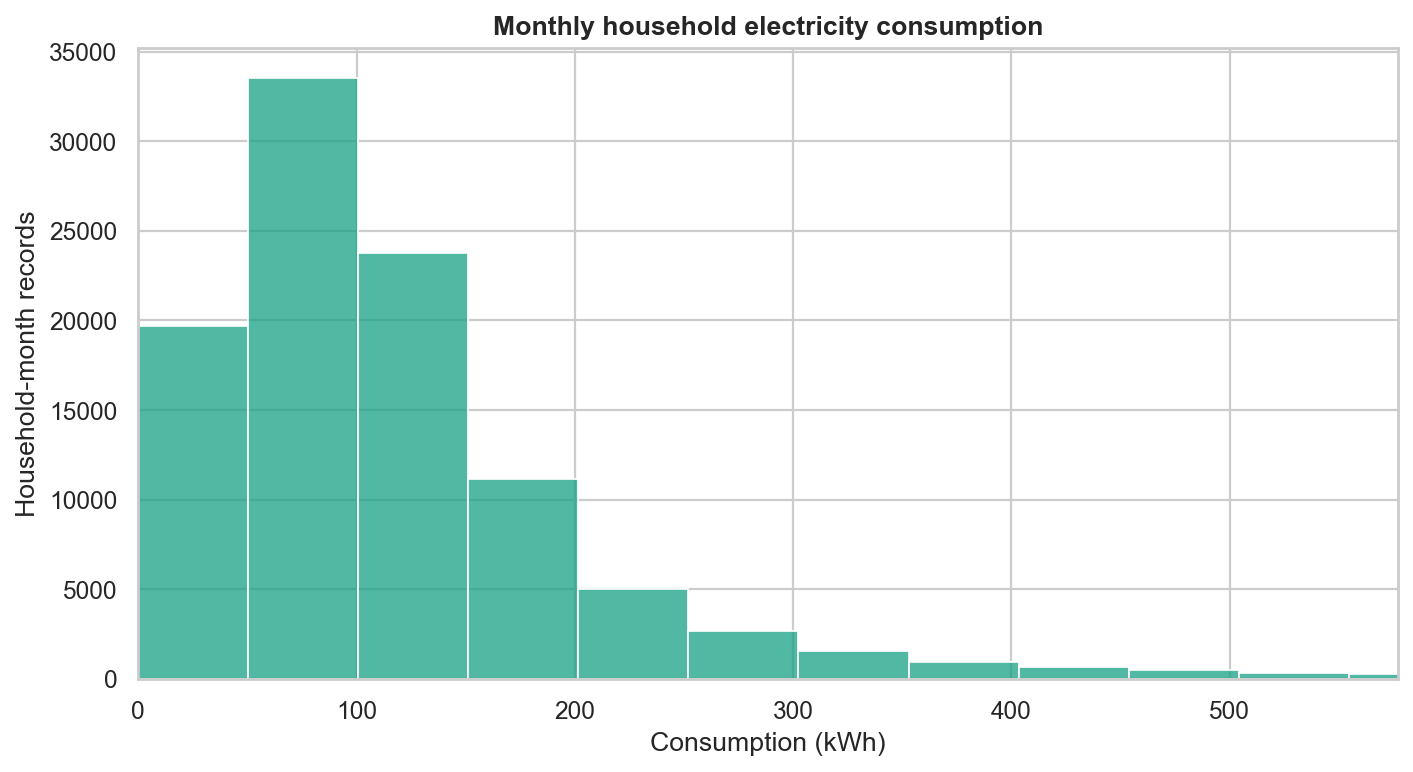

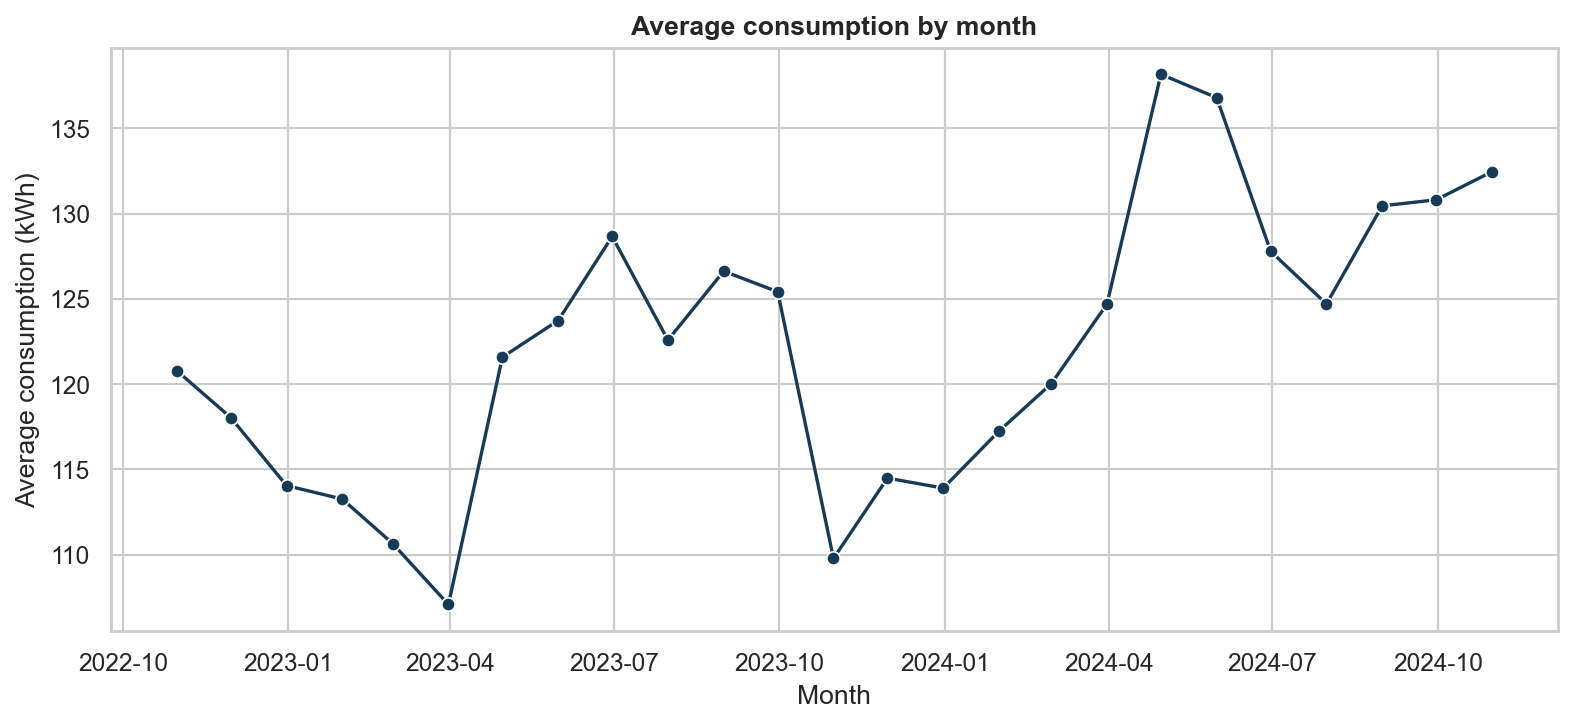

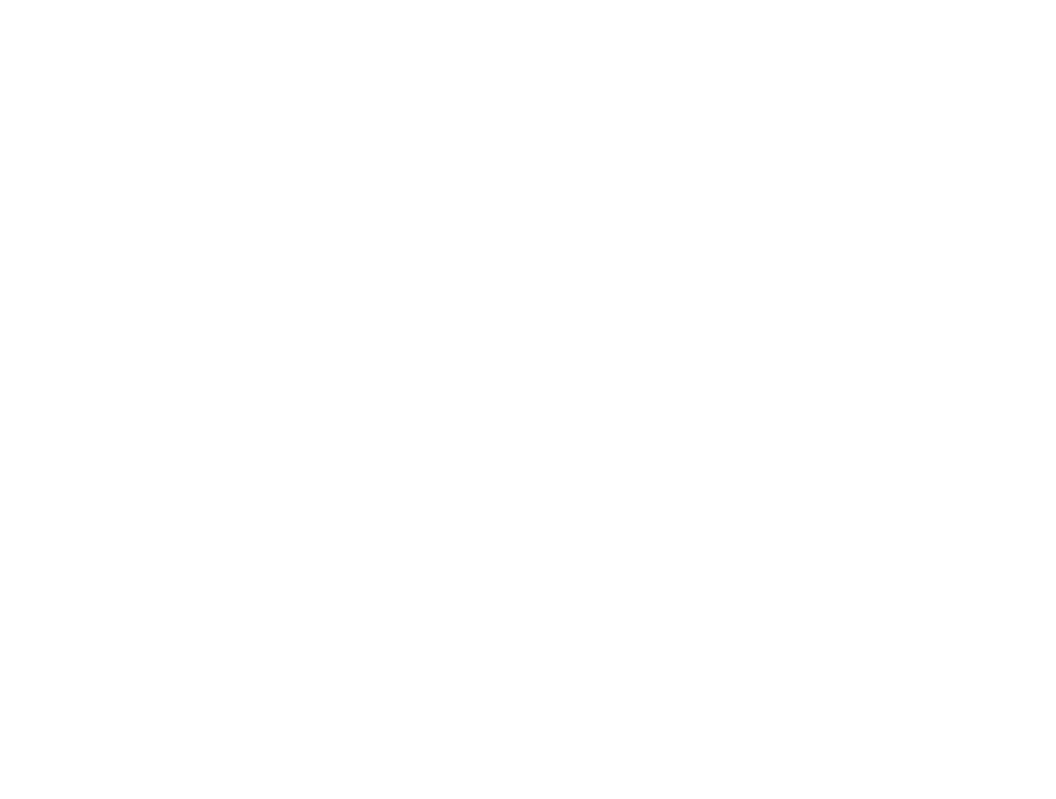

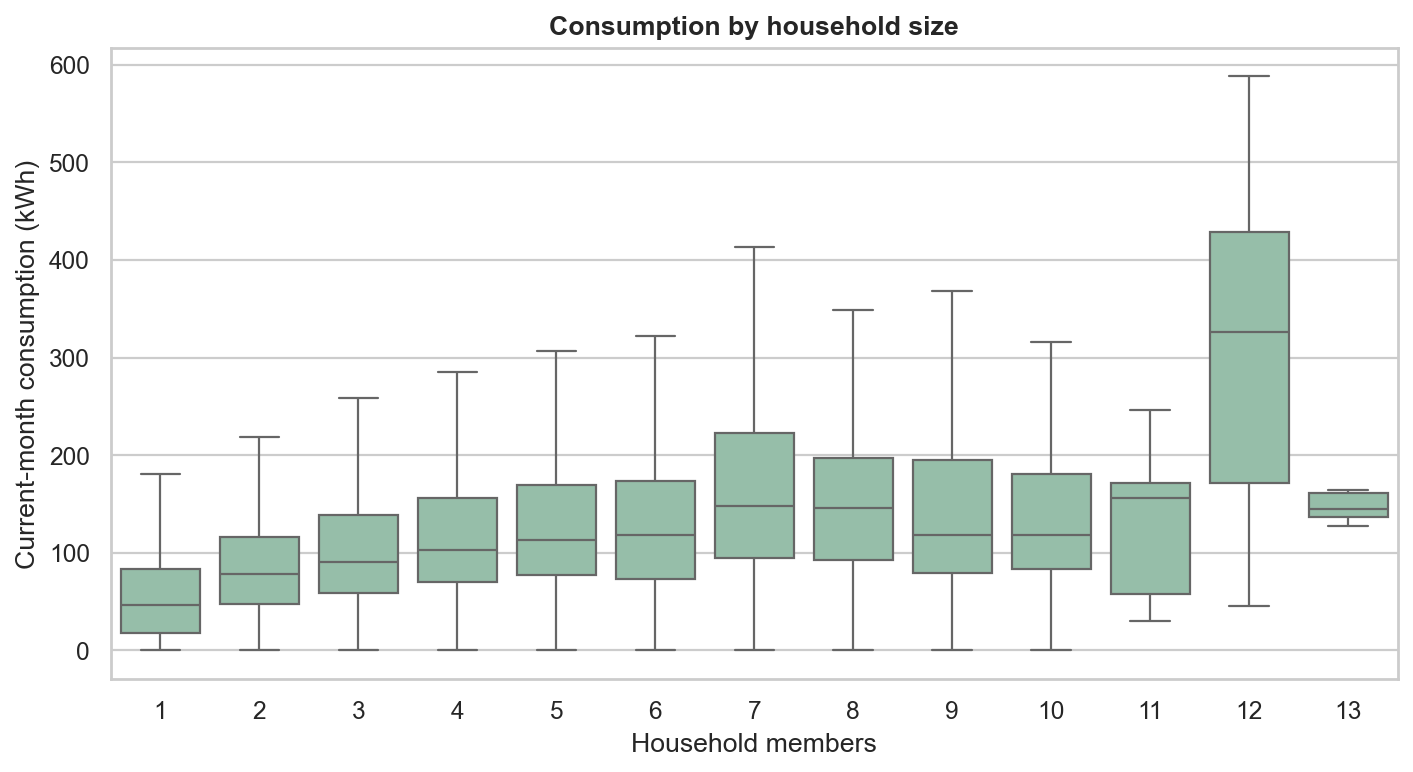

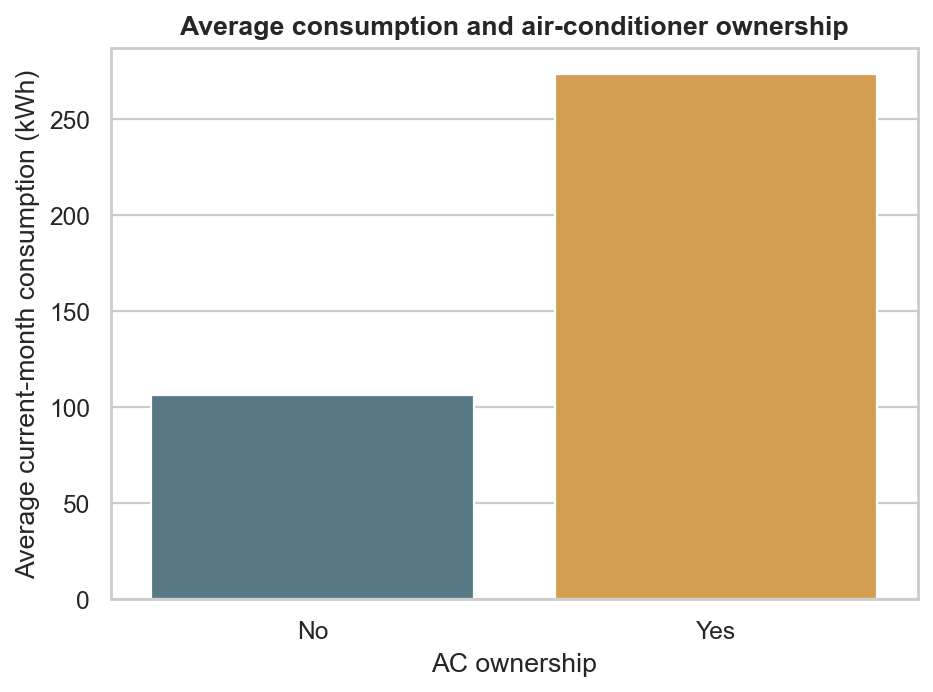

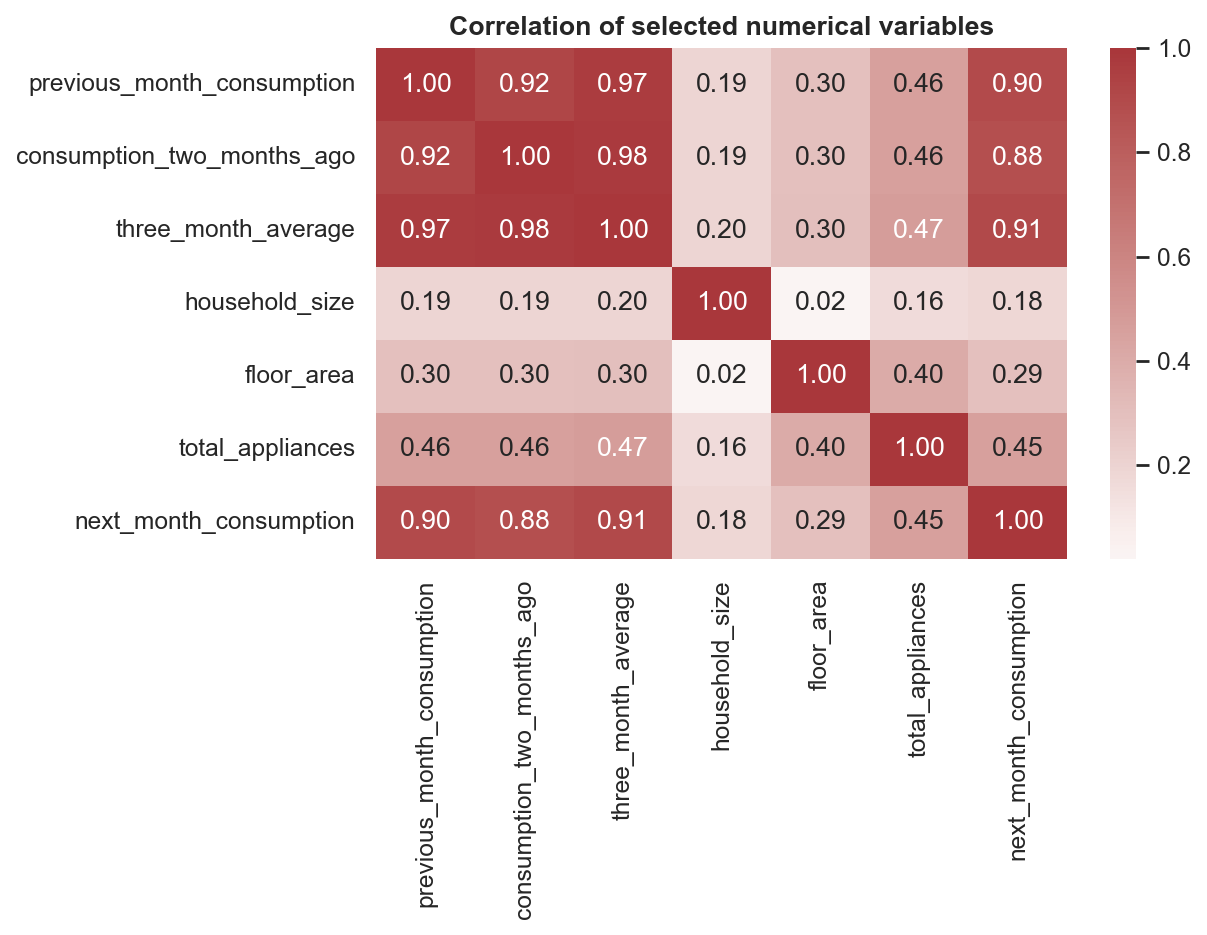

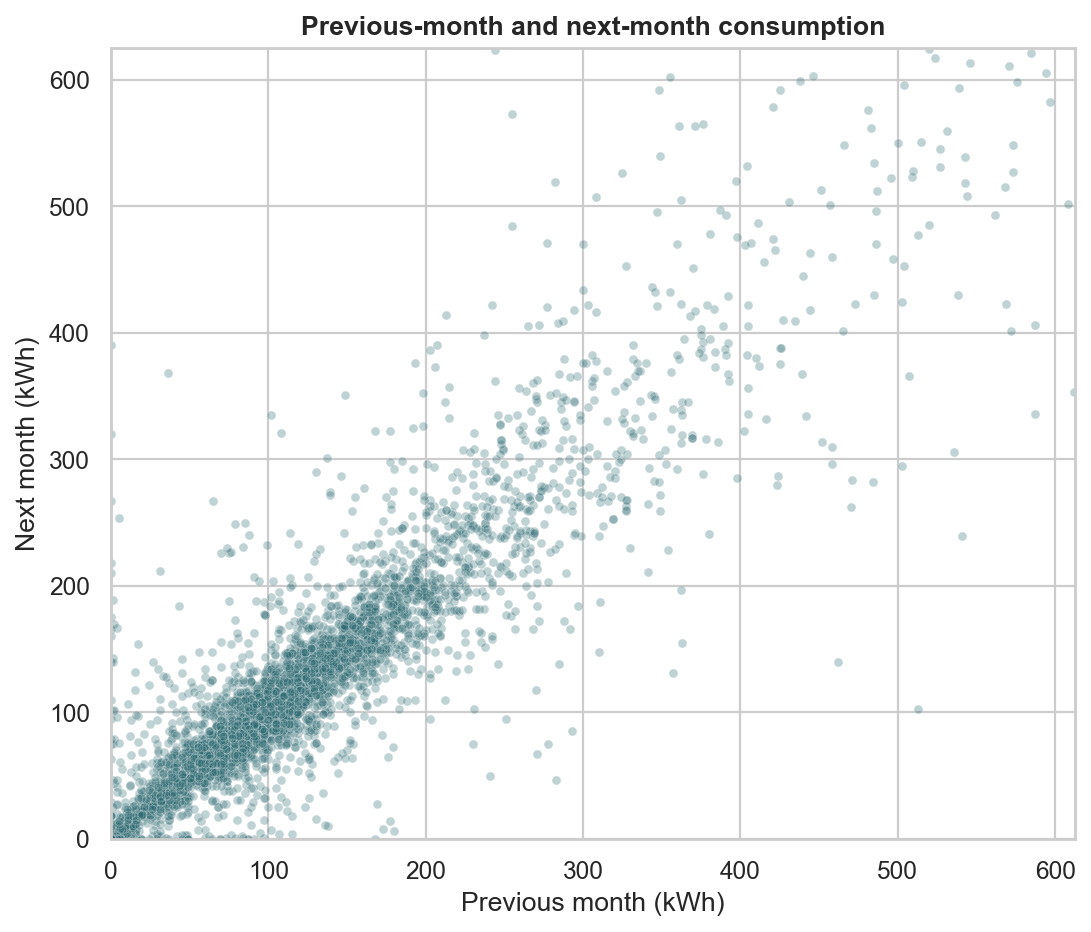

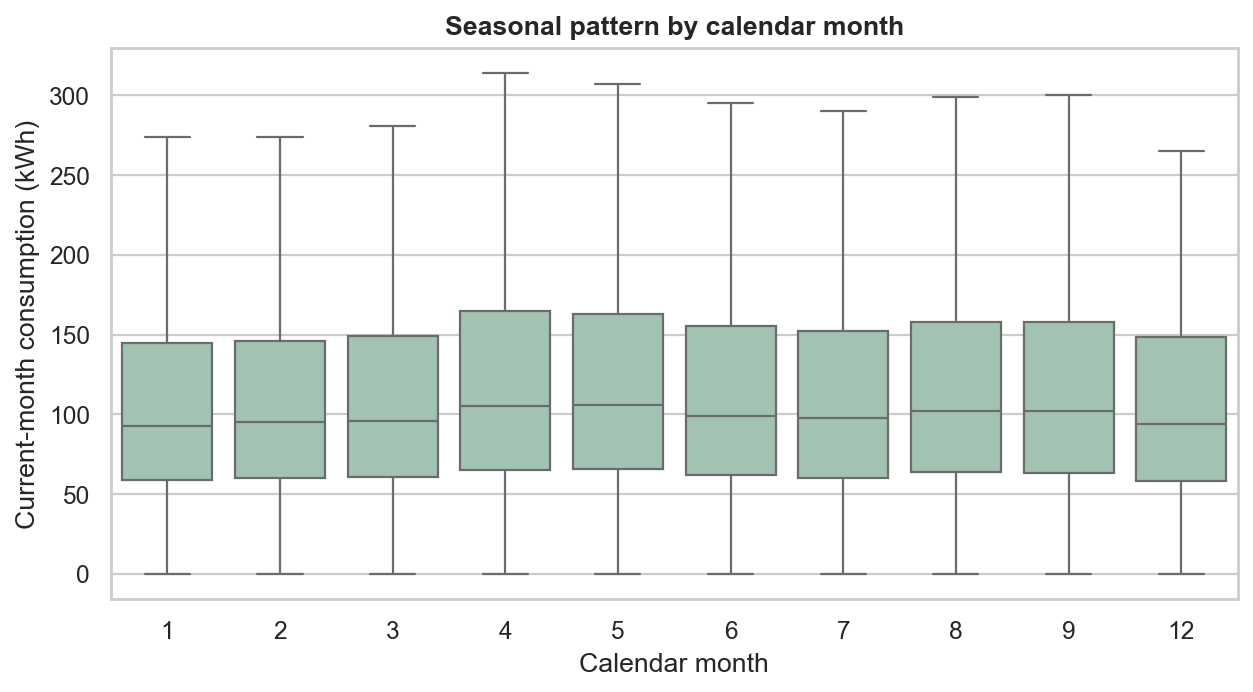

In [4]:
for name in ['01_consumption_distribution.png','02_monthly_average.png','03_target_distribution.png','04_consumption_household_size.png','05_consumption_ac.png','07_correlation_heatmap.png','08_previous_vs_next.png','09_seasonal_pattern.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/name), width=850))

## 8. Feature engineering

All consumption features come from the previous three months. Survey answers are used only from the month-end after Wave 1 was collected. The household ID is kept only for grouping and is not a predictor.

In [5]:
from src.feature_engineering import MODEL_FEATURES, BASE_NUMERIC, BINARY, CATEGORICAL
print('Model feature count:', len(MODEL_FEATURES))
display(pd.DataFrame({'Numerical': pd.Series(BASE_NUMERIC), 'Binary': pd.Series(BINARY), 'Categorical': pd.Series(CATEGORICAL)}))

Model feature count: 34


,Numerical,Binary,Categorical
0,previous_month_consumption,has_refrigerator,csc_area
1,consumption_two_months_ago,has_washing_machine,housing_type
2,consumption_three_months_ago,has_rice_cooker,socio_economic_class
3,three_month_average,has_water_heater,meter_type
4,three_month_max,has_computer,water_heating_method
5,three_month_min,has_television,NaN
6,consumption_change,has_air_conditioner,NaN
7,consumption_percentage_change,home_business,NaN
8,rolling_standard_deviation,solar_generation,NaN
9,month_number,grid_cooking,NaN


## 9. Target creation

Within each household, `shift(-1)` aligns the next month with the current feature row. A value above 90 kWh becomes class 1. The first rows without three months of history and final rows without a next month are removed.

In [6]:
table = pd.read_csv(ROOT/'data/processed/model_table.csv', parse_dates=['month'])
cols=['household_ID','month','consumption','previous_month_consumption','next_month_consumption','high_risk']
display(table[cols].head())
display(pd.read_csv(ROOT/'outputs/tables/threshold_comparison.csv'))
sample_id = table.household_ID.iloc[0]
display(table.loc[table.household_ID.eq(sample_id), cols].head())
print('Manual check: each target value belongs to the month after the feature month within the same household.')

,household_ID,month,consumption,previous_month_consumption,next_month_consumption,high_risk
0,ID0001,2023-12-31,82.0,85,67,0
1,ID0002,2023-12-31,37.0,39,37,0
2,ID0003,2023-12-31,206.0,214,205,1
3,ID0004,2023-12-31,180.0,178,201,1
4,ID0005,2023-12-31,89.0,94,92,1


,Threshold,Value,High count,High percentage,Selected
0,90 kWh,90.0,9389,56.003579,Yes
1,Training 75th percentile,156.0,4150,24.753952,No


,household_ID,month,consumption,previous_month_consumption,next_month_consumption,high_risk
0,ID0001,2023-12-31,82.0,85,67,0
224,ID0001,2024-01-31,67.0,82,92,1
2977,ID0001,2024-02-29,92.0,67,0,0
5732,ID0001,2024-03-31,0.0,92,106,1
8483,ID0001,2024-04-30,106.0,0,63,0


Manual check: each target value belongs to the month after the feature month within the same household.


## 10. Data Leakage Prevention

Past months only create rolling features. Survey collection must happen before the feature month. Preprocessing is inside pipelines fitted on training data. ID is excluded. Test data is used once for the final comparison.

In [7]:
assert 'household_ID' not in MODEL_FEATURES
assert 'next_month_consumption' not in MODEL_FEATURES
assert (table['wave1_date'].isna().sum() == 0)
assert (pd.to_datetime(table.wave1_date) <= table.month).all()
print('Leakage assertions passed: no ID, target value, future survey, or future consumption is a feature.')

Leakage assertions passed: no ID, target value, future survey, or future consumption is a feature.


## 11. Train, validation and test split

The split is by complete calendar month. No calendar month appears in more than one split.

In [8]:
split = pd.read_csv(ROOT/'outputs/tables/split_summary.csv')
display(split)
assert len(set(split['Start month'])) == len(split)
print('Interpretation: the latest usable month is untouched testing data.')

,Split,Start month,End month,Records,Households,Normal,High,High percentage
0,Training,2023-12-31,2024-06-30,16765,2771,7376,9389,56.003579
1,Validation,2024-07-31,2024-08-31,6413,3446,2734,3679,57.367847
2,Testing,2024-09-30,2024-09-30,3759,3759,1535,2224,59.164671


Interpretation: the latest usable month is untouched testing data.


## 12. Preprocessing

Logistic Regression receives median imputation, scaling, and one-hot categories. Tree pipelines impute and encode safely without scaling. CatBoost receives filled strings and uses its native categorical support.

In [9]:
from train_project import make_preprocessor
print(make_preprocessor(scale=True))

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['previous_month_consumption',
                                  'consumption_two_months_ago',
                                  'consumption_three_months_ago',
                                  'three_month_average', 'three_month_max',
                                  'three_month_min', 'consumption_change',
                                  'consumption_percentage_change',
                                  'rolling_standa...
                                  'has_water_heater', 'has_computer',
                                  'has_television', 'has_air_conditioner',
                                  'home_business', 'solar_generation',
                                  'grid_cooking'

## 13. Models and non-default settings

The models include a previous-month rule, Dummy Classifier, Logistic Regression, Decision Tree, Random Forest, XGBoost, and CatBoost.

In [10]:
params = pd.DataFrame([
['Logistic Regression','C=0.5, class_weight=balanced, liblinear','Regularisation and class weighting'],
['Decision Tree','depth=7, leaf=12, split=30','Limits memorisation'],
['Random Forest','180 trees, depth=14, leaf=5, balanced_subsample','Stable nonlinear ensemble'],
['XGBoost','260 trees, rate=.045, depth=5, subsample=.85','Controlled boosting'],
['CatBoost','450 iterations, rate=.045, depth=7, L2=5','Native categories with early stopping'],
], columns=['Model','Important settings','Reason'])
display(params)

,Model,Important settings,Reason
0,Logistic Regression,"C=0.5, class_weight=balanced, liblinear",Regularisation and class weighting
1,Decision Tree,"depth=7, leaf=12, split=30",Limits memorisation
2,Random Forest,"180 trees, depth=14, leaf=5, balanced_subsample",Stable nonlinear ensemble
3,XGBoost,"260 trees, rate=.045, depth=5, subsample=.85",Controlled boosting
4,CatBoost,"450 iterations, rate=.045, depth=7, L2=5",Native categories with early stopping


## 14. Hyperparameter selection

A small manually designed set was compared on training and validation months only. The score was set before testing: 30% balanced accuracy, 20% high-risk recall, 25% F1 and 25% PR-AUC. This gives recall clear weight while still checking both classes, probability ranking and precision-recall balance.

In [11]:
display(pd.read_csv(ROOT/'outputs/tables/hyperparameter_search.csv').round(4))
display(pd.read_csv(ROOT/'outputs/tables/validation_results.csv').round(4))

,Model family,Parameters,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time,Prediction Time,Selection score
0,Random Forest,"depth=10, min_leaf=5",0.9024,0.9027,0.9272,0.9005,0.9137,0.9601,0.9659,0.0,0.0,0.9208
1,Random Forest,"depth=14, min_leaf=5",0.9036,0.9044,0.9303,0.8994,0.9146,0.9604,0.9670,0.0,0.0,0.9216
2,Random Forest,"depth=14, min_leaf=10",0.9024,0.9028,0.9280,0.8997,0.9136,0.9602,0.9670,0.0,0.0,0.9210
3,CatBoost,"depth=6, learning_rate=0.045",0.9022,0.8996,0.9124,0.9176,0.9150,0.9542,0.9572,0.0,0.0,0.9215
4,CatBoost,"depth=7, learning_rate=0.045",0.9032,0.9028,0.9245,0.9051,0.9147,0.9543,0.9586,0.0,0.0,0.9202
5,CatBoost,"depth=7, learning_rate=0.03",0.9032,0.9028,0.9245,0.9051,0.9147,0.9543,0.9586,0.0,0.0,0.9202


,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time,Prediction Time,Selection score
0,Previous-month rule,0.8957,0.8969,0.9266,0.8886,0.9072,0.8969,0.8873,0.0000,0.0000,0.8954
1,Dummy Classifier,0.5737,0.5000,0.5737,1.0000,0.7291,0.5000,0.5737,0.0535,0.0098,0.6757
2,Logistic Regression,0.8859,0.8916,0.9432,0.8524,0.8955,0.9522,0.9613,0.1266,0.0101,0.9022
3,Decision Tree,0.8969,0.8983,0.9282,0.8891,0.9082,0.9527,0.9578,0.1374,0.0098,0.9138
4,Random Forest,0.9024,0.9032,0.9296,0.8978,0.9134,0.9604,0.9669,0.5690,0.0369,0.9206
5,XGBoost,0.8986,0.9019,0.9396,0.8799,0.9088,0.9591,0.9659,0.5645,0.0122,0.9152
6,CatBoost,0.9032,0.9028,0.9245,0.9051,0.9147,0.9543,0.9586,0.5241,0.0038,0.9202
7,Soft Voting Ensemble,0.9000,0.9020,0.9338,0.8888,0.9107,0.9603,0.9669,0.0000,0.0000,0.9178


## 15. Class imbalance

At 90 kWh, 56.00% of training samples are high risk. Both classes are well above 10%, so the fixed 90 kWh definition is usable. Class weights are still used where supported to keep attention on both classes.

In [12]:
display(pd.read_csv(ROOT/'outputs/tables/threshold_comparison.csv').round(2))

,Threshold,Value,High count,High percentage,Selected
0,90 kWh,90.0,9389,56.00,Yes
1,Training 75th percentile,156.0,4150,24.75,No


## 16. Model evaluation

Balanced accuracy, recall, F1 and PR-AUC matter because ordinary accuracy can hide missed high isk homes. A false negative means the model says normal although the next month is high.

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time,Prediction Time
0,Random Forest,0.9013,0.9034,0.9381,0.8921,0.9145,0.9632,0.9723,0.5690,0.0325
1,CatBoost,0.9016,0.9015,0.9296,0.9020,0.9156,0.9549,0.9595,0.5241,0.0030
2,Previous-month rule,0.9016,0.8998,0.9229,0.9096,0.9162,0.8998,0.8930,0.0000,0.0000
3,Soft Voting Ensemble,0.8957,0.8992,0.9395,0.8804,0.9090,0.9630,0.9710,0.0000,0.0000
4,Decision Tree,0.8944,0.8986,0.9419,0.8754,0.9075,0.9547,0.9637,0.1374,0.0065
5,XGBoost,0.8907,0.8957,0.9424,0.8683,0.9038,0.9620,0.9719,0.5645,0.0081
6,Logistic Regression,0.8787,0.8885,0.9543,0.8350,0.8906,0.9554,0.9685,0.1266,0.0068
7,Dummy Classifier,0.5916,0.5000,0.5916,1.0000,0.7434,0.5000,0.5916,0.0535,0.0068


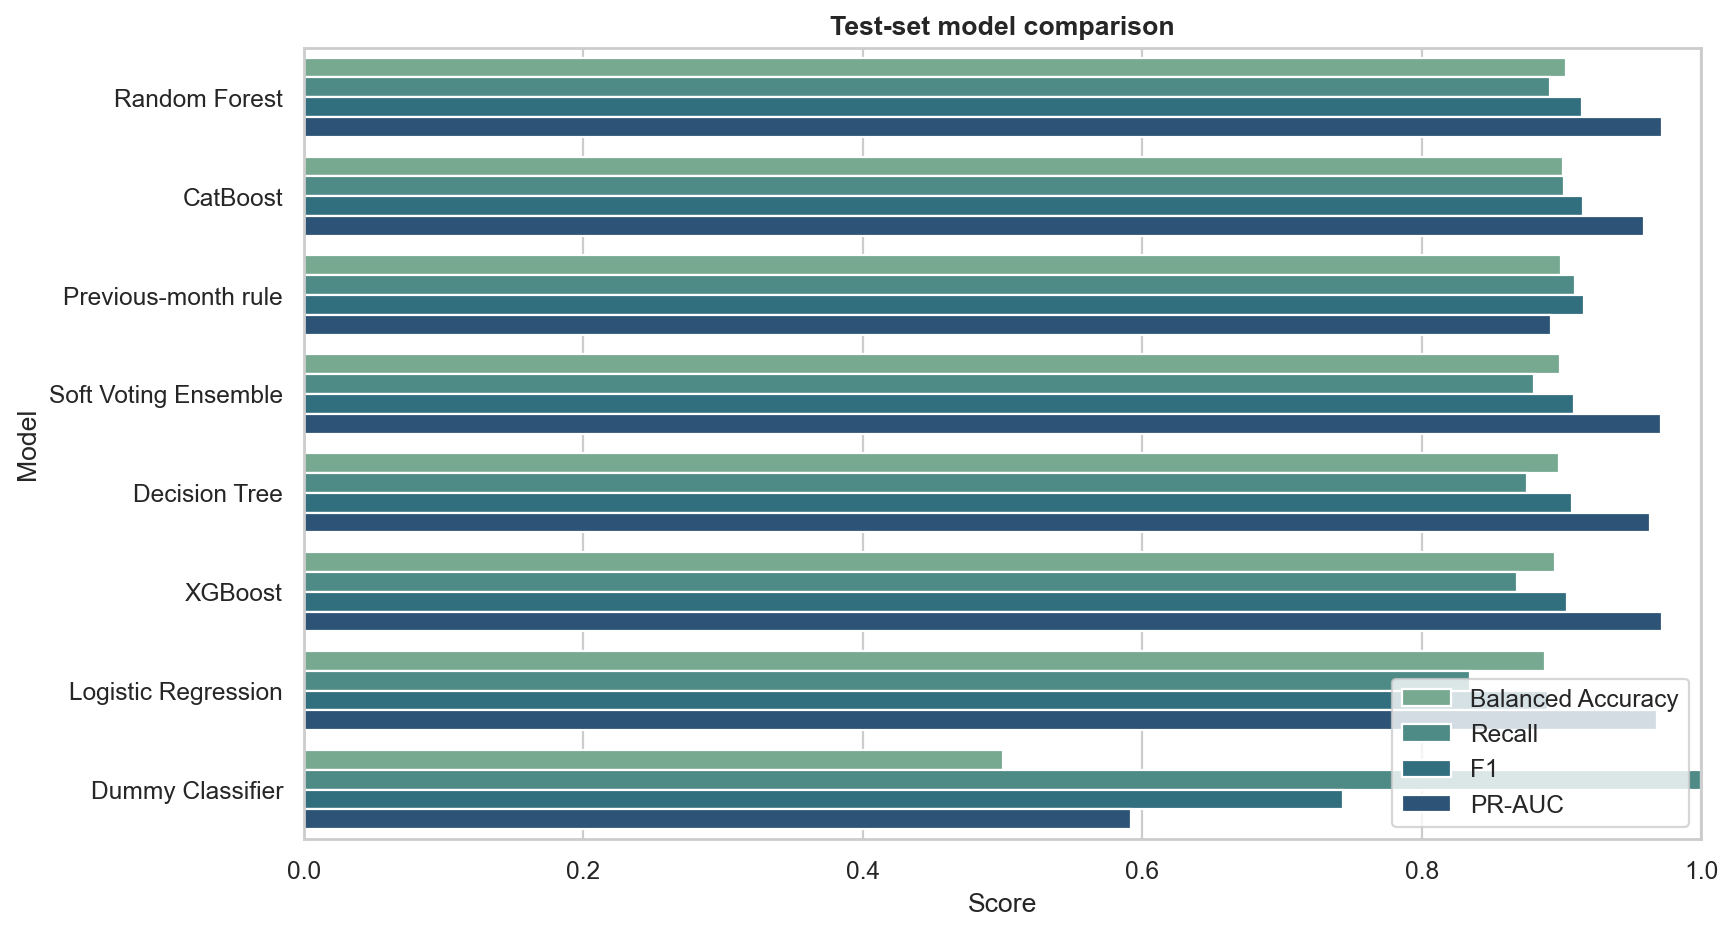

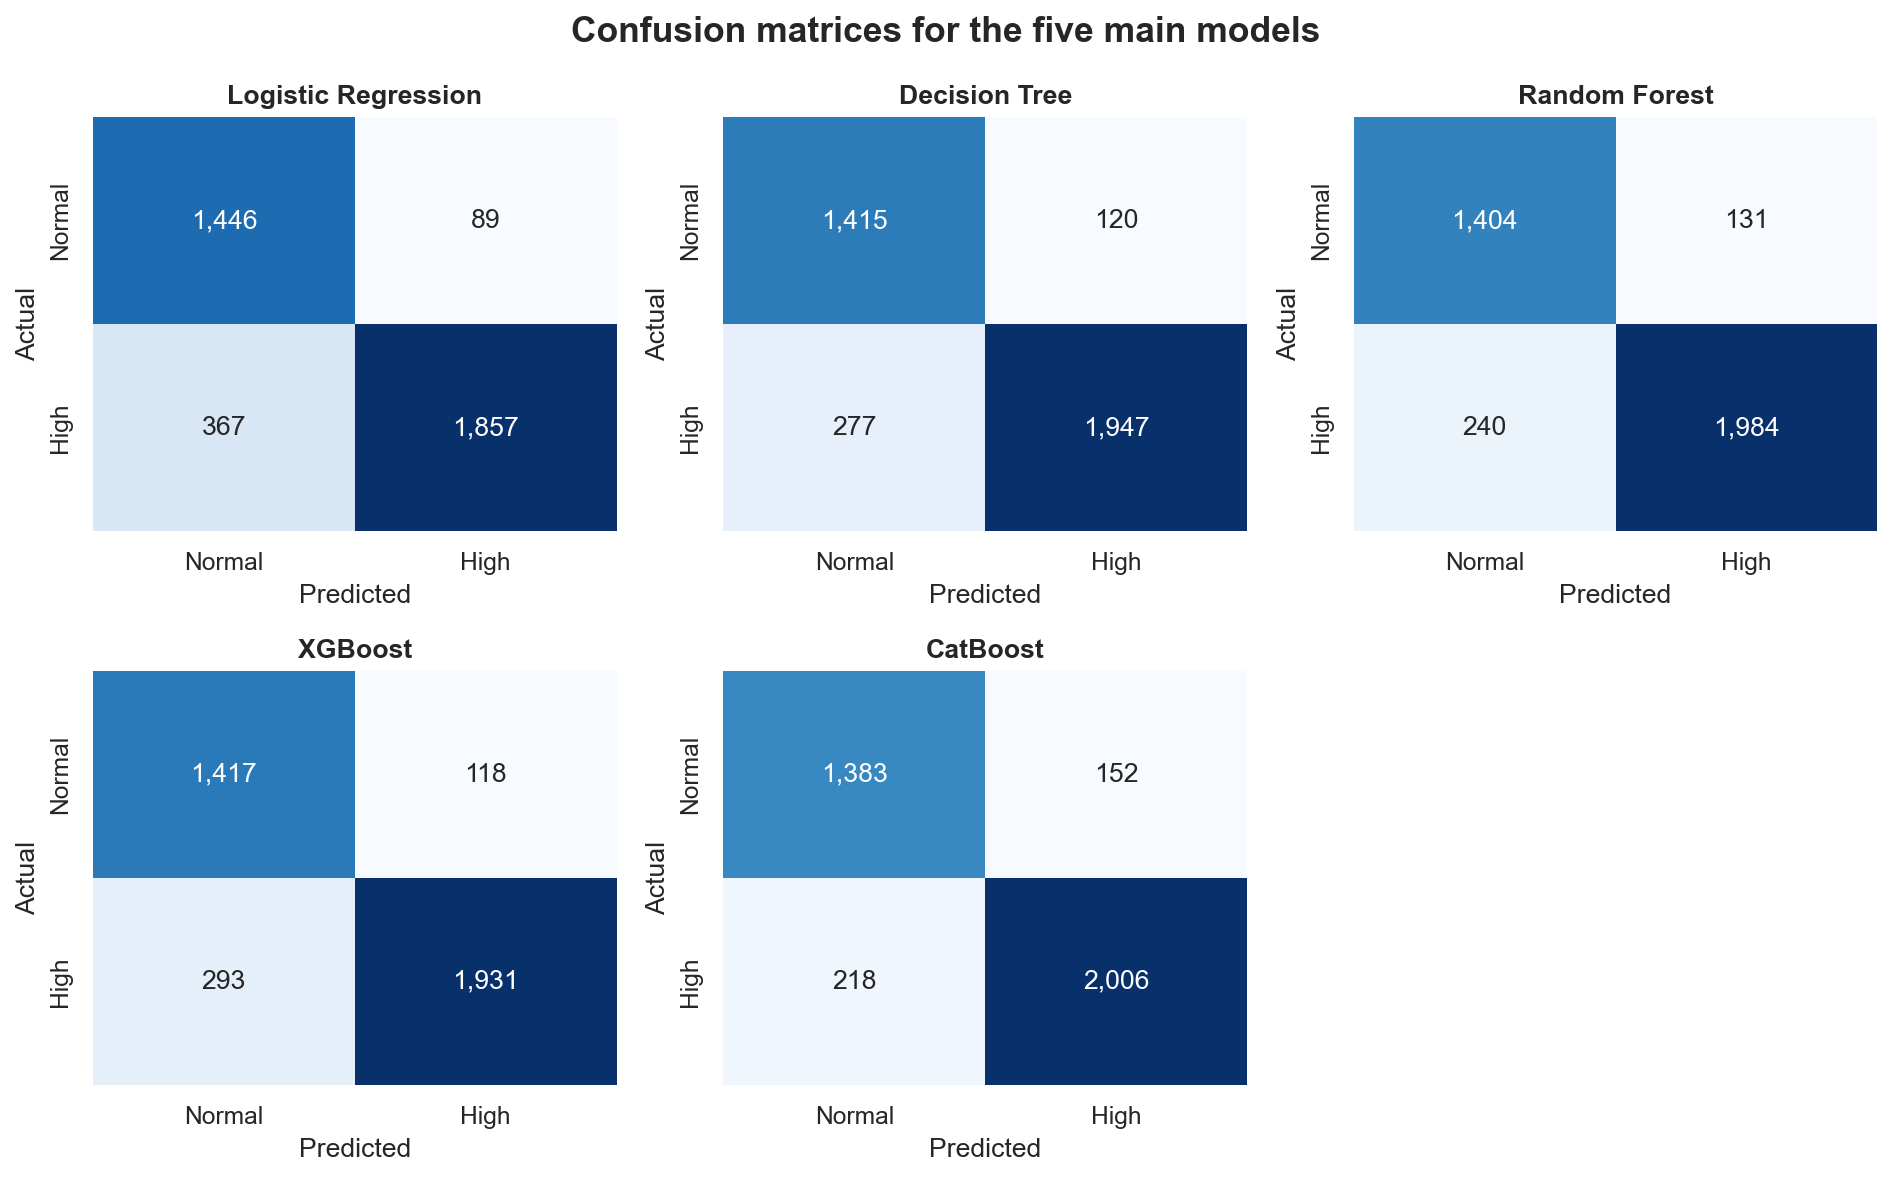

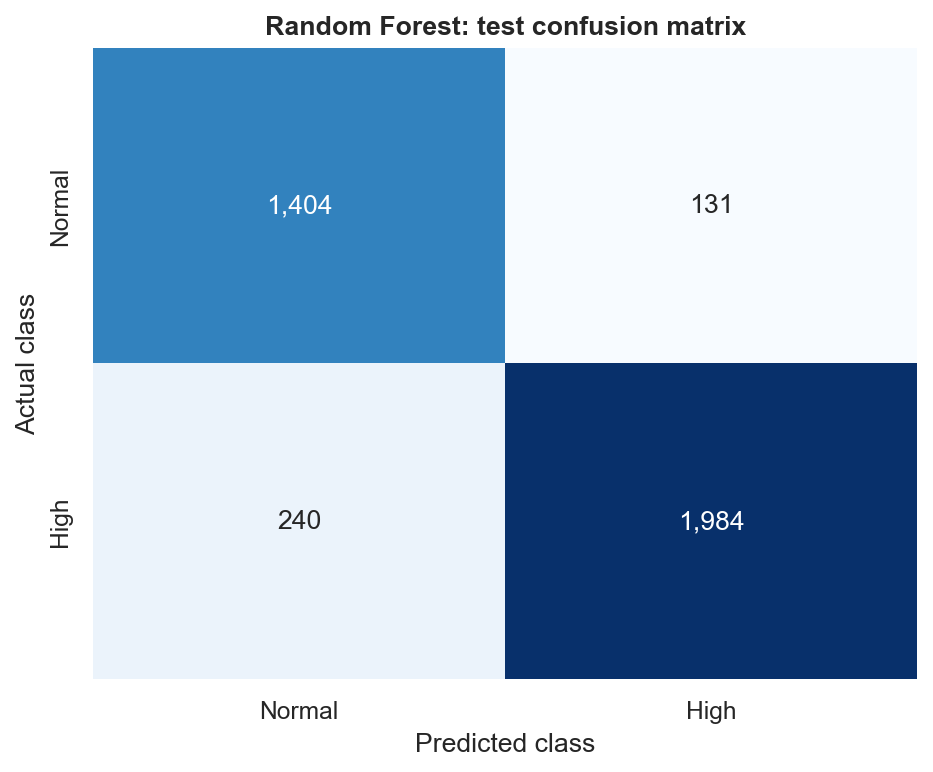

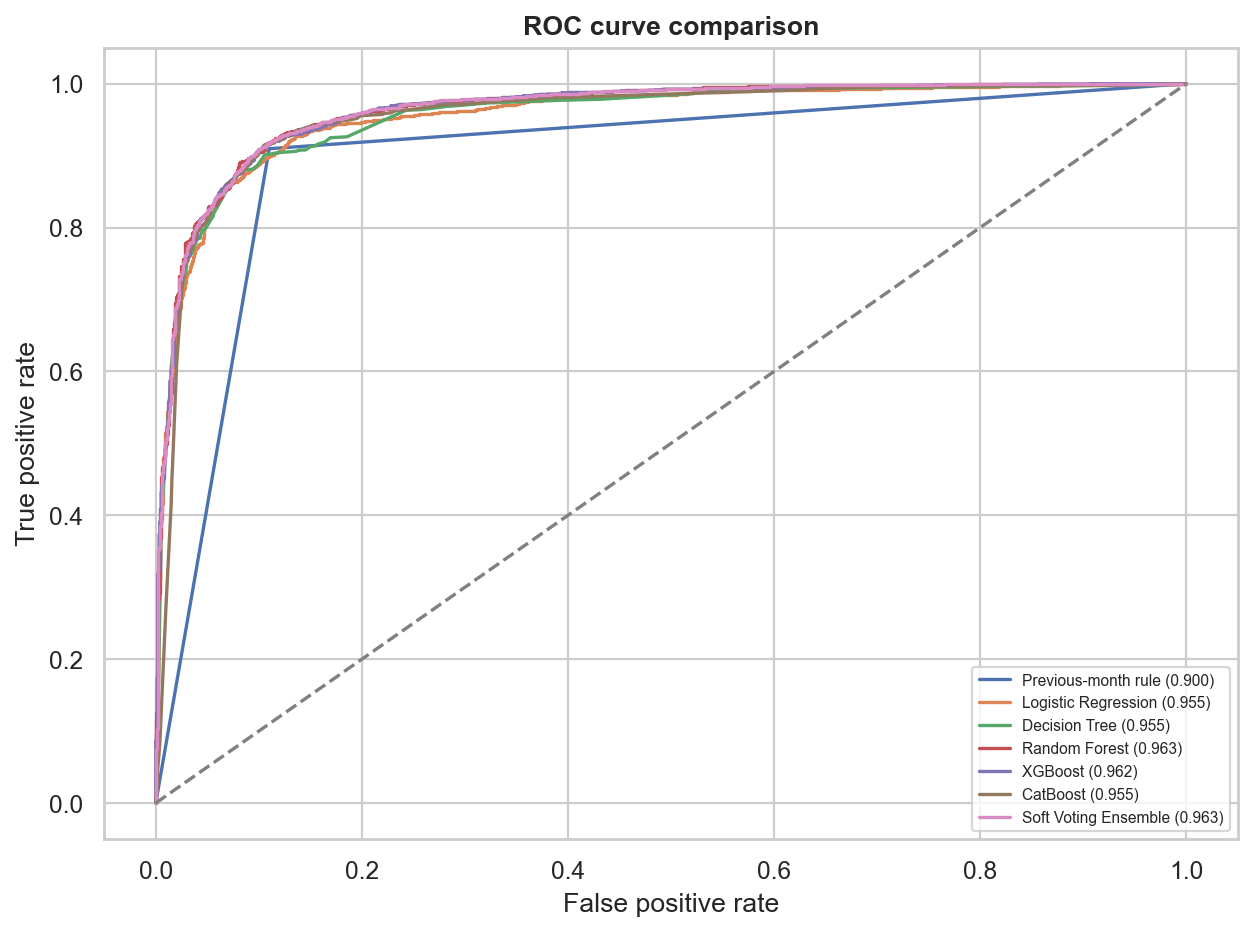

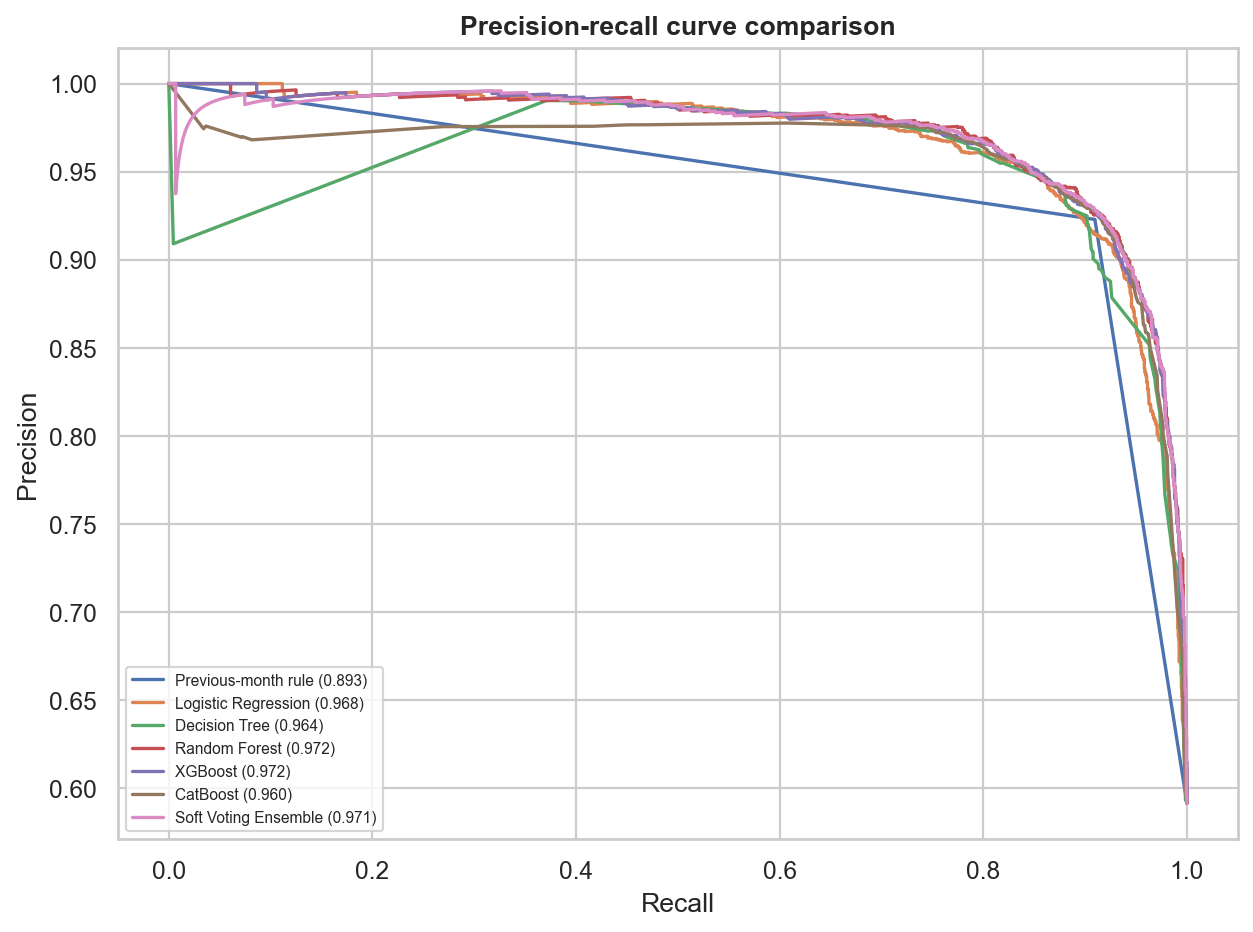

In [13]:
comparison = pd.read_csv(ROOT/'outputs/tables/model_comparison.csv')
display(comparison.round(4))
for name in ['10_model_comparison.png','19_all_model_confusion_matrices.png','13_confusion_matrix.png','11_roc_curve.png','12_precision_recall_curve.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/name), width=850))

## 17. Strengths and limitations by model

In [14]:
strengths=pd.DataFrame([
['Logistic Regression','Fast and clear','Limited nonlinear patterns','Fast','Fast','Low','Needs one-hot','High','Good baseline'],
['Decision Tree','Easy rules','Can overfit','Fast','Fast','High','Needs encoding','High','Useful comparison'],
['Random Forest','Stable nonlinear performance','Larger model','Medium','Fast','High','Needs encoding','Medium','Selected'],
['XGBoost','Strong ranking performance','More tuning','Medium','Fast','High','Needs encoding','Medium','Strong alternative'],
['CatBoost','Native categories','More specialised','Medium','Very fast','High','Native','Medium','Very close alternative']],
columns=['Model','Main strength','Main limitation','Training','Prediction','Nonlinear','Categories','Explainability','Suitability'])
display(strengths)

,Model,Main strength,Main limitation,Training,Prediction,Nonlinear,Categories,Explainability,Suitability
0,Logistic Regression,Fast and clear,Limited nonlinear patterns,Fast,Fast,Low,Needs one-hot,High,Good baseline
1,Decision Tree,Easy rules,Can overfit,Fast,Fast,High,Needs encoding,High,Useful comparison
2,Random Forest,Stable nonlinear performance,Larger model,Medium,Fast,High,Needs encoding,Medium,Selected
3,XGBoost,Strong ranking performance,More tuning,Medium,Fast,High,Needs encoding,Medium,Strong alternative
4,CatBoost,Native categories,More specialised,Medium,Very fast,High,Native,Medium,Very close alternative


## 18. Hybrid ensemble

A soft vote averaged validation-selected Random Forest, CatBoost and XGBoost probabilities. It did not improve validation selection score or test performance enough to justify extra complexity.

In [15]:
display(comparison.loc[comparison.Model.isin(['Random Forest','CatBoost','XGBoost','Soft Voting Ensemble'])].round(4))

,Model,Accuracy,Balanced Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Training Time,Prediction Time
0,Random Forest,0.9013,0.9034,0.9381,0.8921,0.9145,0.9632,0.9723,0.5690,0.0325
1,CatBoost,0.9016,0.9015,0.9296,0.9020,0.9156,0.9549,0.9595,0.5241,0.0030
3,Soft Voting Ensemble,0.8957,0.8992,0.9395,0.8804,0.9090,0.9630,0.9710,0.0000,0.0000
5,XGBoost,0.8907,0.8957,0.9424,0.8683,0.9038,0.9620,0.9719,0.5645,0.0081


## 19. Explainable AI

Feature importance is global. SHAP gives the direction and size of feature contributions. These are associations learned by the model, not proof of cause.

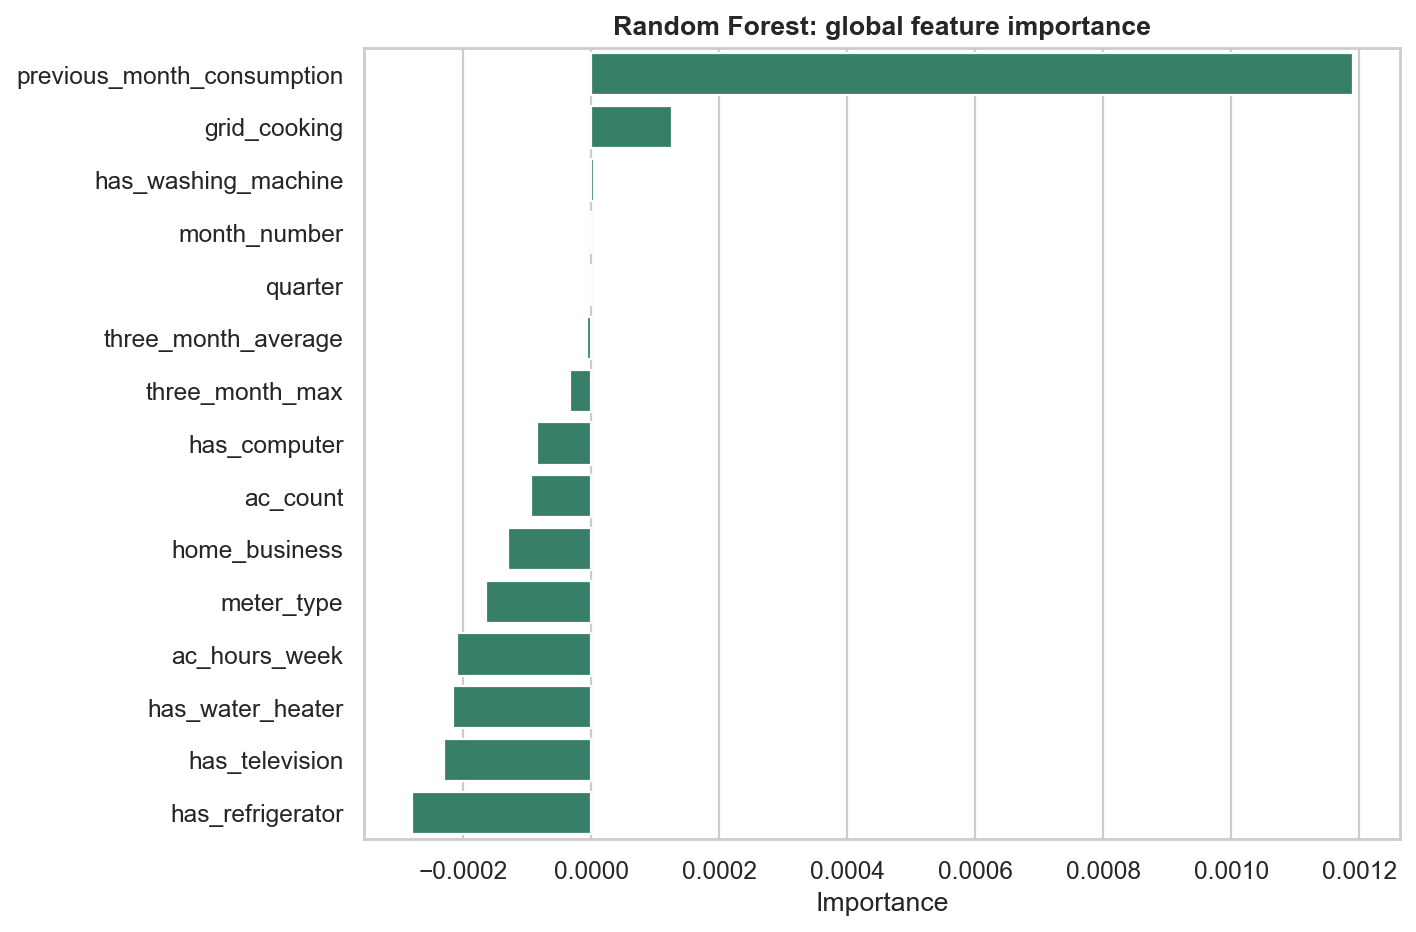

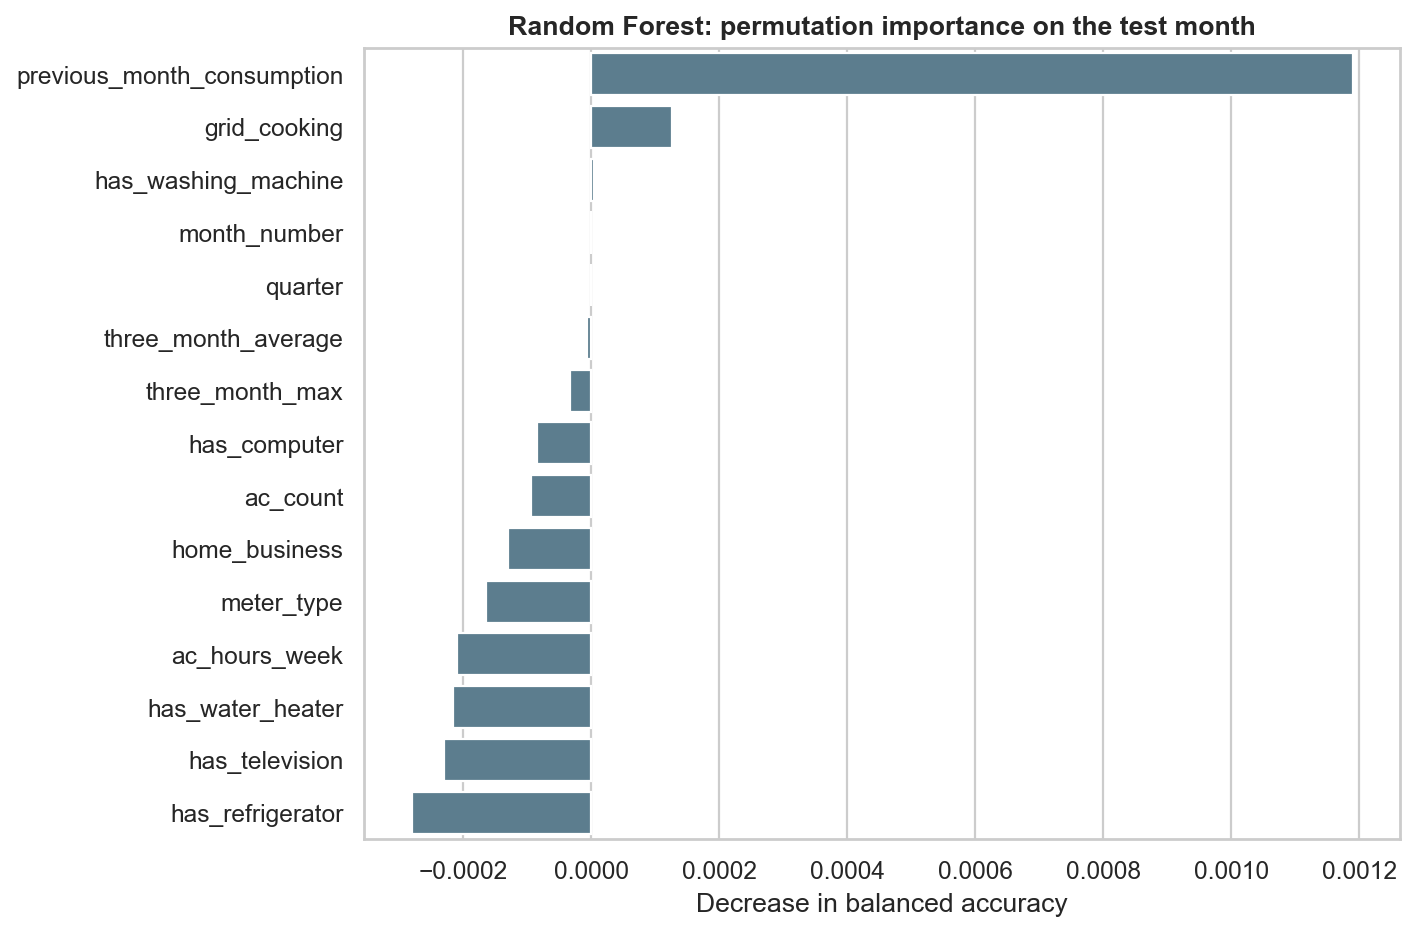

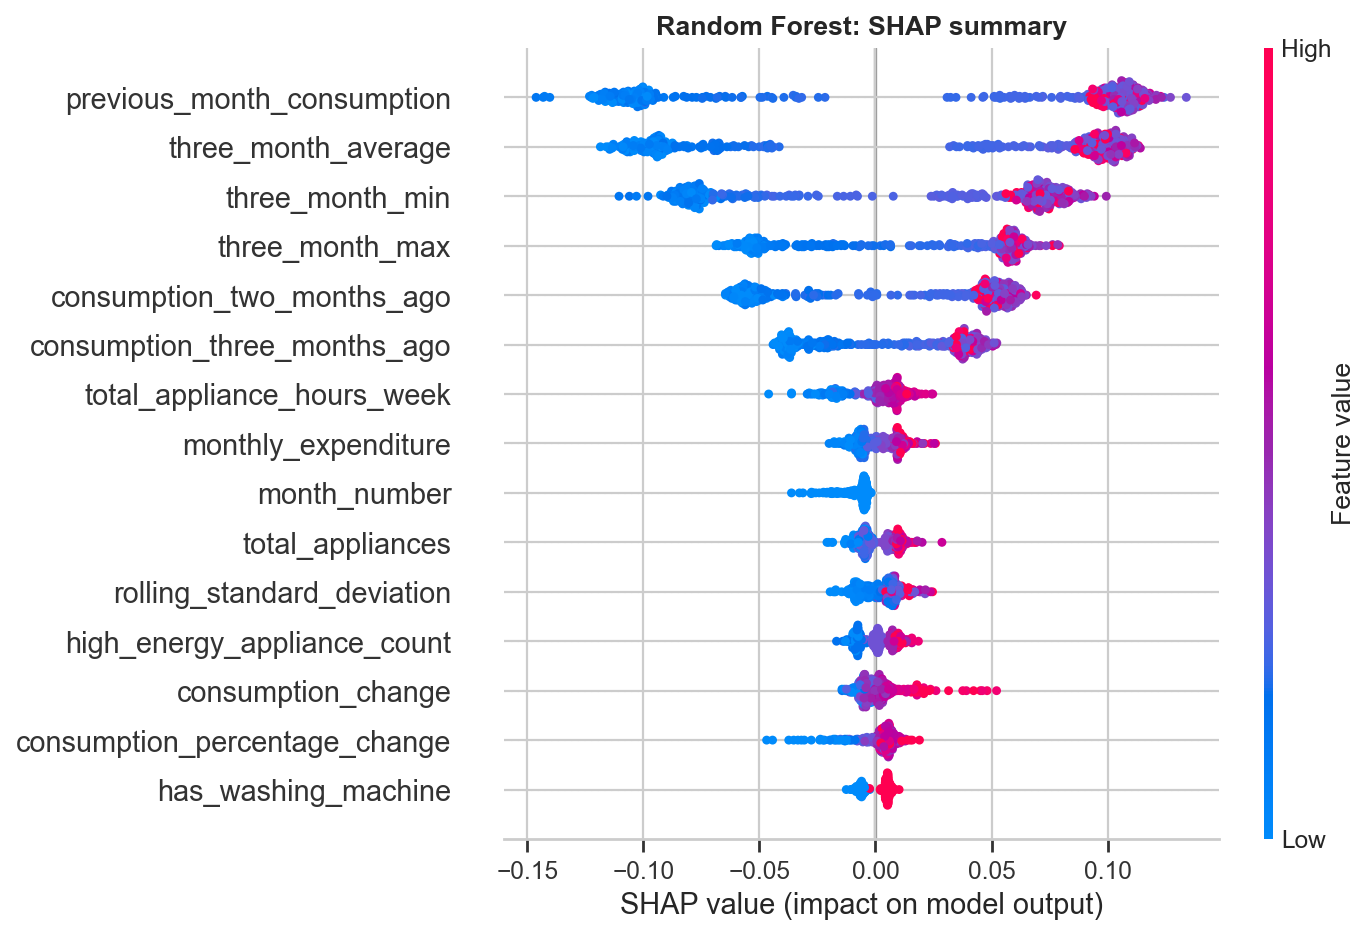

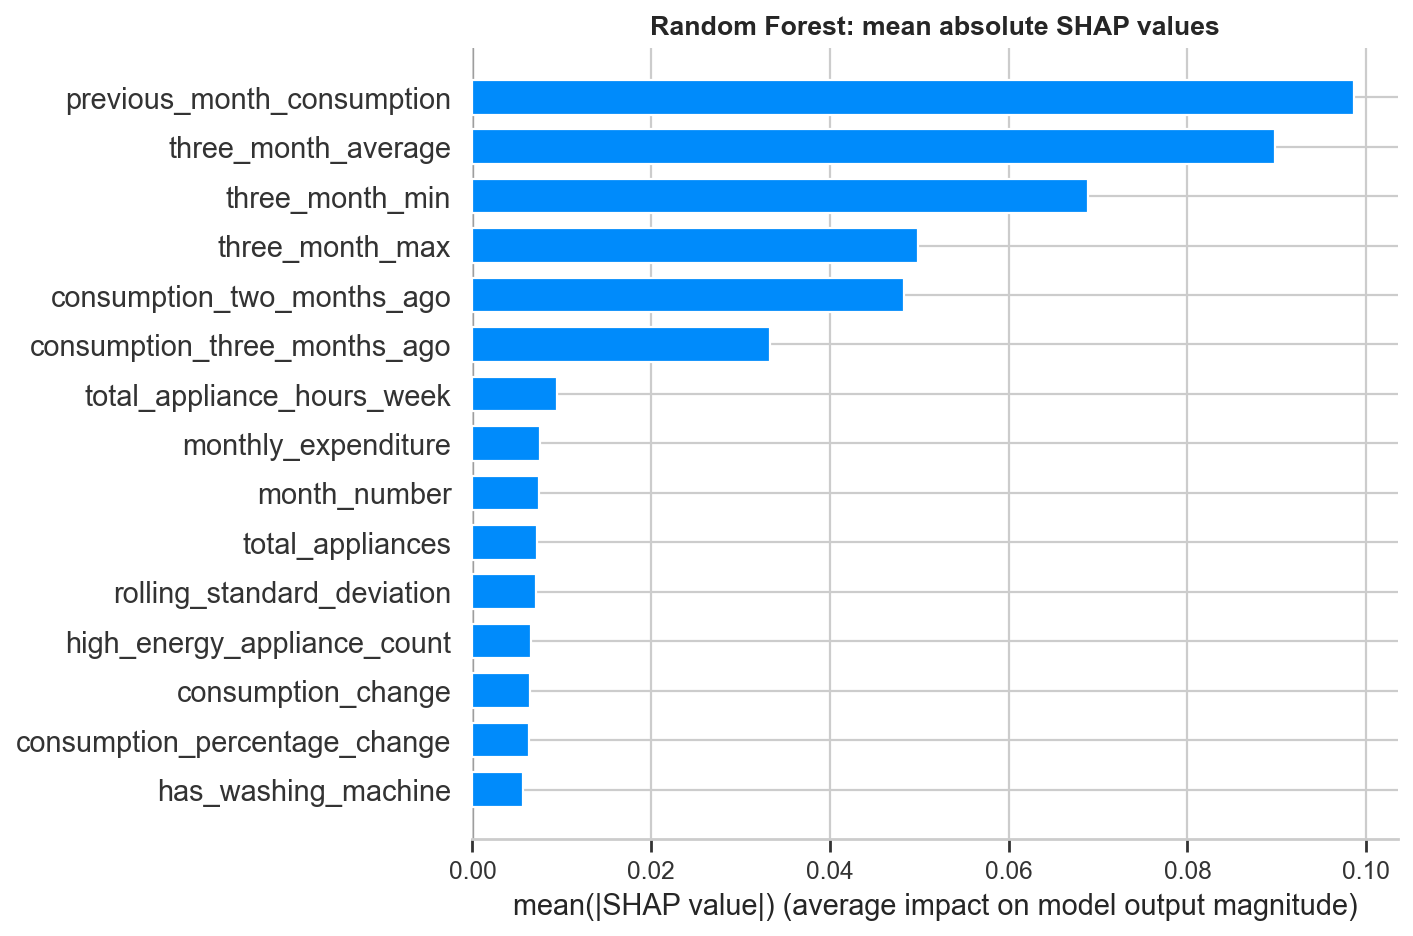

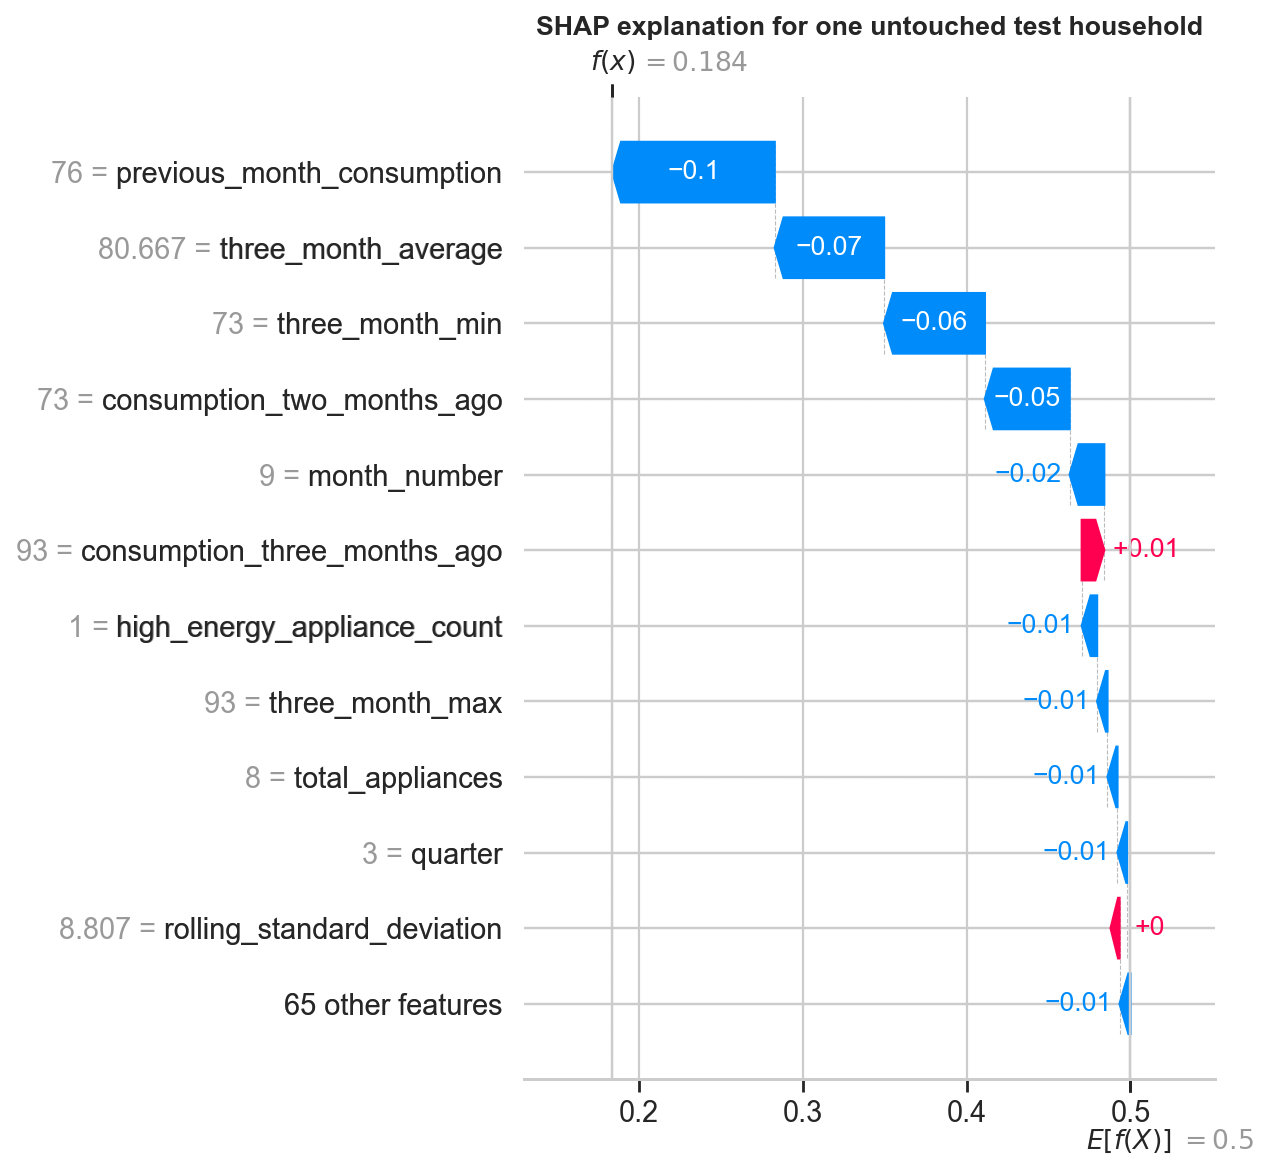

In [16]:
for name in ['14_feature_importance.png','15_permutation_importance.png','16_shap_summary.png','17_shap_bar.png','18_shap_waterfall.png']:
    display(Image(filename=str(ROOT/'outputs/figures'/name), width=850))

## 20. Fairness and ethics

Names, phone numbers, addresses and account numbers are not used. Household income-related information is sensitive and must not be used to penalise a household. RECON-SL covers selected cities, so geographic representation is limited. Groups with fewer than 50 test records are not displayed. Differences below are a warning for monitoring, not proof of unfair treatment. This is decision support, not a final authority.

In [17]:
display(pd.read_csv(ROOT/'outputs/tables/fairness_by_group.csv').round(4))

,Field,Group,Records,Accuracy,Balanced Accuracy,High-risk Recall
0,csc_area,ALUTHGAMA,139,0.8633,0.8603,0.8696
1,csc_area,AMBALANGODA,117,0.9402,0.9399,0.9298
2,csc_area,BORALASGAMUWA,130,0.9077,0.9008,0.9158
3,csc_area,DALUGAMA,115,0.8696,0.8826,0.8421
4,csc_area,GALLE,182,0.9066,0.9107,0.8929
5,csc_area,HIKKADUWA,130,0.8846,0.8956,0.9375
6,csc_area,JA-ELA,106,0.8868,0.8871,0.9038
7,csc_area,KALUTARA,176,0.8693,0.8725,0.8172
8,csc_area,KANDANA,104,0.9038,0.9134,0.8873
9,csc_area,KESELWATTA,188,0.8777,0.8865,0.8378


## 21. Single-sample inference

The sample below is from the untouched test month and is passed through the saved preprocessing and model workflow.

In [18]:
single=json.loads((ROOT/'outputs/tables/single_sample_prediction.json').read_text())
display(single)
display(pd.read_csv(ROOT/'outputs/tables/single_prediction_shap.csv').head(10))

{'household_ID_anonymised': 'Test household 1',
 'feature_month': '2024-09-30',
 'actual_class': 1,
 'predicted_class': 0,
 'probability': 0.18355685609315914,
 'correct': False}

,Feature,SHAP value,Value,abs_shap
0,previous_month_consumption,-0.099244,76.000000,0.099244
1,three_month_average,-0.066753,80.666667,0.066753
2,three_month_min,-0.061563,73.000000,0.061563
3,consumption_two_months_ago,-0.051774,73.000000,0.051774
4,month_number,-0.021124,9.000000,0.021124
5,consumption_three_months_ago,0.013753,93.000000,0.013753
6,high_energy_appliance_count,-0.009372,1.000000,0.009372
7,three_month_max,-0.006343,93.000000,0.006343
8,total_appliances,-0.006106,8.000000,0.006106
9,quarter,-0.005845,3.000000,0.005845


## 22. Select final model

Random Forest was selected from validation results. CatBoost was a very close alternative and had slightly higher test recall, but the test result was not used to change the earlier selection.

In [19]:
meta=json.loads((ROOT/'models/model_metadata.json').read_text())
print('Selected model:',meta['model_name'])
display(pd.Series(meta['test_metrics']).round(4).to_frame('Test value'))

Selected model: Random Forest


,Test value
Accuracy,0.9013
Balanced Accuracy,0.9034
Precision,0.9381
Recall,0.8921
F1,0.9145
ROC-AUC,0.9632
PR-AUC,0.9723
Training Time,0.5690
Prediction Time,0.0325


## 23. Save and reload model

The complete preprocessing and classifier are saved together. Metadata and the input schema keep the app consistent.

In [20]:
import joblib
loaded=joblib.load(ROOT/'models/energy_risk_model.pkl')
display(json.loads((ROOT/'outputs/tables/model_reload_test.json').read_text()))
print('Model type:',type(loaded).__name__)

{'model_loaded': True,
 'prediction_matches': True,
 'probability': 0.18355685609315914}

Model type: EnergyRiskModelBundle


## 24. Streamlit frontend

`app.py` loads the saved model, validates real model fields, shows probability, local SHAP factors, saving ideas, and a privacy notice. It never asks for personal identifiers.

In [21]:
print('Run locally with: streamlit run app.py')

Run locally with: streamlit run app.py


## 25. Reusable prediction function

`src/predict.py` receives one dictionary, creates derived features, validates values, applies the saved workflow, and returns class, probability, label, or a useful error.

In [22]:
from src.predict import predict_household
print(predict_household({'previous_month_consumption': 40}, model=loaded))

{'predicted_class': None, 'probability': None, 'risk_label': None, 'error': "'consumption_two_months_ago'"}


## 26. Tests

Automated tests cover file loading, schema loading, valid inference, missing fields, unknown categories, negative values and probability bounds.

In [23]:
print('Run: pytest -q')

Run: pytest -q


## 27. README and reproducibility

The README gives data paths, installation, notebook, app, results, ethics and limitations. Raw data is excluded from Git to protect privacy and avoid large uploads.

## 28. Existing-approach and literature comparison

The project compares a persistence rule with classical and ensemble ML. The source paper and dataset documentation are listed in the README. No published score is copied because tasks and samples differ.

In [24]:
literature=pd.DataFrame([
['Previous-month rule','RECON-SL monthly','Next-month risk','Threshold rule','Same project metrics','Simple','No household detail','Our baseline'],
['Logistic Regression','RECON-SL monthly + Wave 1','Next-month risk','Linear classifier','Seven metrics','Clear','Limited curves','Our baseline ML'],
['Random Forest','RECON-SL monthly + Wave 1','Next-month risk','Bagged trees','Seven metrics','Stable','Larger model','Our selected model'],
['XGBoost','RECON-SL monthly + Wave 1','Next-month risk','Boosted trees','Seven metrics','Strong ranking','Tuning','Alternative'],
['CatBoost','RECON-SL monthly + Wave 1','Next-month risk','Categorical boosting','Seven metrics','Native categories','Specialised','Research question model']],columns=['Approach','Data used','Task','Method','Measurements','Strength','Limitation','Difference'])
display(literature)

,Approach,Data used,Task,Method,Measurements,Strength,Limitation,Difference
0,Previous-month rule,RECON-SL monthly,Next-month risk,Threshold rule,Same project metrics,Simple,No household detail,Our baseline
1,Logistic Regression,RECON-SL monthly + Wave 1,Next-month risk,Linear classifier,Seven metrics,Clear,Limited curves,Our baseline ML
2,Random Forest,RECON-SL monthly + Wave 1,Next-month risk,Bagged trees,Seven metrics,Stable,Larger model,Our selected model
3,XGBoost,RECON-SL monthly + Wave 1,Next-month risk,Boosted trees,Seven metrics,Strong ranking,Tuning,Alternative
4,CatBoost,RECON-SL monthly + Wave 1,Next-month risk,Categorical boosting,Seven metrics,Native categories,Specialised,Research question model


## 29. Final discussion

Random Forest had the best validation selection score by a very small margin and the best test balanced accuracy. CatBoost handled categories effectively and had slightly higher test recall, but changing the selected model after seeing test results would be leakage. The hybrid did not justify its complexity. Past consumption features were most influential. Performance is encouraging for the next calendar month, but the one-month test window and selected-city survey limit wider claims. New households can be processed if they provide the same fields, but external testing is still needed.

## 30. Final conclusion

This project used real RECON-SL monthly electricity and household survey data to predict whether the following month would exceed 90 kWh. Seven approaches and a soft-voting ensemble were compared. Random Forest was selected using validation data and achieved 0.9034 balanced accuracy, 0.8921 high-risk recall, 0.9145 F1 and 0.9723 PR-AUC on the untouched September 2024 test month. Recent consumption was the strongest influence. The system can support early awareness.